# 03 - Modèles de détection

On compare 3 approches sur le même jeu de test :
- **Random Forest** (supervisé)
- **XGBoost** (supervisé)
- **Isolation Forest** (non supervisé : entraîné sur du trafic normal seulement, détecte ce qui s'en écarte)

**Métriques :** on regarde surtout le *rappel* (part des attaques détectées) et le *F1*, pas l'accuracy.

In [1]:
import sys; sys.path.append('..')
import pandas as pd
from src import evaluate as ev

## 1. Charger les données prétraitées
`TRAIN_SAMPLE` limite la taille du train pour aller vite (le test reste complet). Mets `None` pour tout utiliser.

In [2]:
TRAIN_SAMPLE = 300_000
X_train, y_train, X_test, y_test = ev.load_data(train_sample=TRAIN_SAMPLE)
print('train:', X_train.shape, '| test:', X_test.shape)
print('part d attaques train:', round(y_train.mean(), 3), '| test:', round(y_test.mean(), 3))

train: (300000, 68) | test: (76992, 68)
part d attaques train: 0.082 | test: 0.082


## 2. Entraîner et comparer
Cette cellule peut prendre quelques minutes.

In [3]:
table, preds, models = ev.run_all(X_train, y_train, X_test, y_test)
table

,precision,recall,f1,roc_auc,temps_entraînement_s
modèle,,,,,
Random Forest,0.9998,0.9997,0.9998,0.9999,17.9
XGBoost,0.9989,0.9997,0.9993,0.9999,11.3
Isolation Forest,0.3173,0.1019,0.1542,0.7678,4.8


## 3. Matrices de confusion
Chaque case : combien de flux bien ou mal classés. Les **faux négatifs** (attaques ratées) sont les plus dangereux.

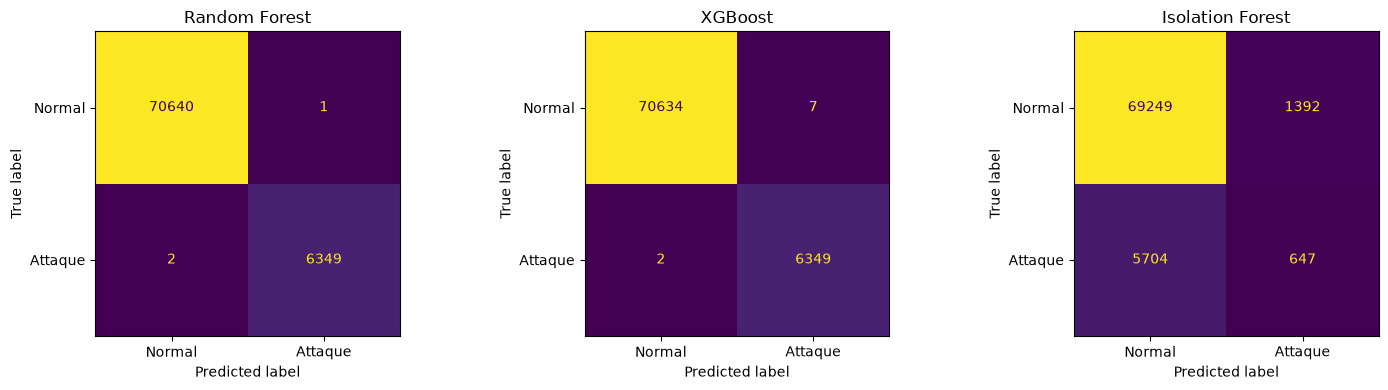

In [4]:
fig = ev.save_confusion_matrices(y_test, preds)

## 4. Features les plus importantes (Random Forest)

Avg Fwd Segment Size      0.119453
Fwd Packet Length Mean    0.089598
Bwd Packet Length Mean    0.056136
Destination Port          0.045818
Subflow Fwd Bytes         0.043330
Fwd Packet Length Max     0.038624
Packet Length Variance    0.036694
Fwd Header Length         0.034584
Bwd Packet Length Min     0.033829
Bwd Packet Length Max     0.032591
Avg Bwd Segment Size      0.030760
Packet Length Std         0.030372
Fwd Header Length.1       0.030289
Packet Length Mean        0.029008
Max Packet Length         0.028308
dtype: float64

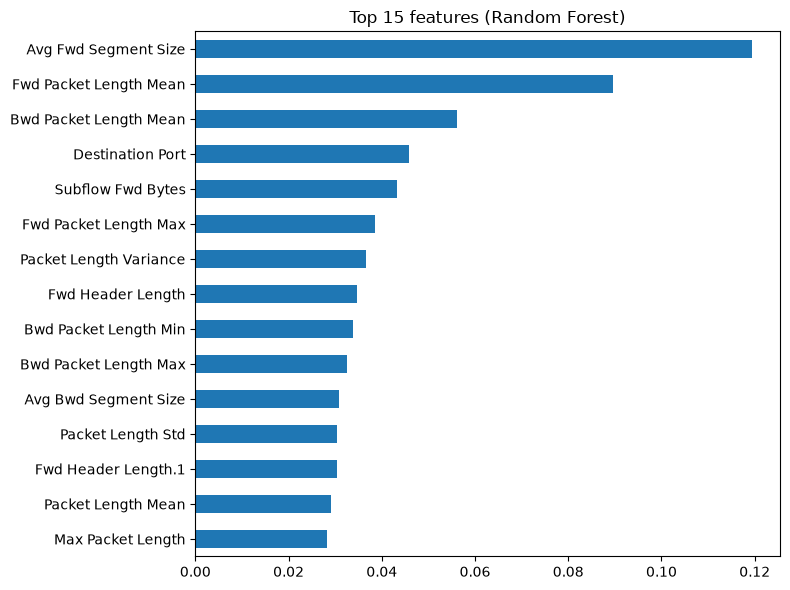

In [5]:
imp = ev.save_feature_importance(models['Random Forest'], X_train.columns)
imp.sort_values(ascending=False)

In [6]:
table.to_csv('../results/model_comparison.csv')
print('résultats sauvegardés')

résultats sauvegardés


## Observations
*(à compléter par toi : quel modèle est le meilleur ? lequel rate le plus d'attaques ? pourquoi ?)*

## Observations
- Random Forest et XGBoost obtiennent des scores très élevés : F1 = 0,9998 et 0,9993, rappel = 0,9997 pour les deux. Ils détectent presque toutes les attaques.
- Random Forest a la meilleure précision (0,9998), donc très peu de fausses alertes. XGBoost est le plus rapide à entraîner (6 s contre 16 s).
- Isolation Forest est très faible : F1 = 0,15, rappel = 0,10. Il ne détecte qu'environ 1 attaque sur 10. Il est entraîné uniquement sur du trafic normal, mais le trafic normal est très varié, donc beaucoup d'attaques ressemblent à du trafic normal pour lui.
- Les modèles supervisés (qui voient des exemples d'attaques) sont donc bien meilleurs que le modèle non supervisé sur ce dataset.
- Features les plus importantes : Avg Fwd Segment Size, Fwd Packet Length Mean, Bwd Packet Length Mean, Destination Port. La taille des paquets permet de distinguer les attaques du trafic normal.
- Limite : ces scores sont très élevés car l'échantillon est facile (50 000 premières lignes de chaque fichier, surtout DDoS, FTP-Patator, slowloris, PortScan). Les résultats finaux devront utiliser les fichiers complets et être évalués classe par classe.